# Estudios reproducibles: de la pregunta económica a un registro portátil

**¿Cómo conservamos datos, supuestos y diagnósticos para que otra persona pueda examinar un resultado?**

Ejecutamos tres ejemplos sin conexión: un VAR monetario recursivo con observaciones mexicanas congeladas, una transferencia calibrada a hogares escrita en declaraciones DP `.mod` y un escenario arancelario con una red productiva OCDE. Comparten la interfaz de registro y exportación, no una interpretación causal. Use Python 3.11 o posterior y Puremacro 5.6.0: `python -m pip install "puremacro[notebooks]==5.6.0"`. Seleccione el kernel de ese entorno y conserve `notebooks/_nbstyle.py` junto al cuaderno (o descargue la carpeta de fuentes). También puede instalar una copia del código 5.6.0 con `python -m pip install -e ".[notebooks]"`.

| Experimento | Evidencia y choque | Lo que no establece |
|---|---|---|
| México | Observaciones mensuales OCDE/FRED congeladas, enero de 2000–diciembre de 2023; innovación de 25 puntos base en la tasa anualizada | Una sorpresa monetaria identificada externamente |
| Hogares | Calibración trimestral ilustrativa; transferencia externa de 0.05 unidades por hogar | Ajuste a encuesta, financiamiento fiscal o equilibrio general |
| Arancel | OCDE ICIO, edición 2023, año 2019; arancel estadounidense de 5% sobre manufacturas mexicanas | Un pronóstico causal de política, PIB o bienestar |

Véanse la [guía de flujos](https://jalonso1979.github.io/puremacro/docs/es/study_workflows/) y el [cuaderno en inglés](69_reproducible_studies.ipynb).

## El método en matemáticas

El VAR estima $x_t=c+\sum_{j=1}^{p}A_jx_{t-j}+u_t$, con $\Sigma_u=PP'$ y $P$ triangular inferior. Para la coordenada de tasas $k$, la respuesta normalizada en niveles es
$$IRF_h=\Psi_h P e_k\,\frac{0.25}{P_{kk}}.$$
El experimento de hogares resta dos trayectorias con idéntica distribución inicial y valores terminales:
$$\Delta C_t+\Delta A_{t+1}=(1+r)\Delta A_t+\tau_t,\qquad \Delta A_0=0.$$
Las respuestas arancelarias son $100(Y_c^{tariff}/Y_c^{base}-1)$, donde $Y_c$ es producción bruta a precios base. Son tres convenciones de respuesta distintas.

## Intuición

**Intuición.** Un número guardado es evidencia incompleta. El mismo coeficiente puede representar un cambio mensual, una innovación en puntos porcentuales anualizados o un cambio relativo de una cantidad del modelo. Declaramos esas elecciones antes de resolver, examinamos diagnósticos después y archivamos insumos junto con resultados. Los hashes detectan alteraciones; no certifican identificación ni autentican al autor del registro.

## Código ejecutable

Todos los insumos vienen con el paquete. No se usan descargas, claves ni servicios de modelos. Las etiquetas de las gráficas y el código son idénticos en ambas ediciones.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
from tempfile import TemporaryDirectory
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _nbstyle
_nbstyle.apply_style()
from puremacro.examples.study_workflows import mexico_data, run_household, run_tariff
from puremacro.study import (
    StudySpec, VariableSpec, run_study, compare_studies, save_study, load_study,
)

SEED = 734

### 1. México: un VAR recursivo declarado

El cargador verifica los hashes de los archivos incluidos. Las columnas ya representan inflación interanual del IPC y tasa interbancaria a tres meses anualizada; no aplicamos logaritmos, diferencias ni anualización adicional. No se registró la fecha original de descarga: no son vintages en tiempo real. Fuentes: [inflación OCDE/FRED](https://fred.stlouisfed.org/series/CPALTT01MXM659N) y [tasa interbancaria](https://fred.stlouisfed.org/series/IR3TIB01MXM156N).

Estas observaciones OCDE distribuidas por FRED son datos de terceros, fuera de la licencia MIT del código. Cite a la OCDE y conserve la atribución al compartir. El manifiesto incluido contiene fuentes, hashes, citas y las [condiciones de reutilización OCDE](https://www.oecd.org/en/about/terms-conditions.html); la fecha original de descarga sigue siendo desconocida.

La inflación precede a la tasa en el orden recursivo de dos variables. Se impone que no responda contemporáneamente a la innovación identificada de tasas. El VAR incluye seis rezagos mensuales y constante; los horizontes van de 0 a 18. Las bandas de 90% usan 199 remuestreos de residuos con semilla y normalización fija del choque estimado. Son puntuales, no simultáneas. Este pequeño conjunto de información puede producir una respuesta positiva de precios.

In [2]:
data = mexico_data()
spec = StudySpec(
    name="Mexico recursive rate innovation", method="var_cholesky",
    variables=(VariableSpec("inflation_yoy", "percentage points"),
               VariableSpec("rate_3m", "percentage points per annum")),
    responses=("inflation_yoy", "rate_3m"), shock="rate_3m", frequency="M",
    identification="recursive", ordering=("inflation_yoy", "rate_3m"),
    lags=6, horizon=18, shock_size=0.25, ci=0.90, n_boot=199, seed=SEED,
)
assert data.index.equals(pd.period_range("2000-01", "2023-12", freq="M"))
assert data.shape == (288, 2) and np.isfinite(data.to_numpy()).all()
print(data.head().round(3).to_string())
print(json.dumps(asdict(spec), indent=2))
mexico = run_study(data, spec)
irf = mexico.to_frame()
impact = irf.loc[irf.horizon.eq(0)].set_index("response").estimate
np.testing.assert_allclose(impact.loc["rate_3m"], 0.25, atol=1e-13)
np.testing.assert_allclose(impact.loc["inflation_yoy"], 0.0, atol=1e-13)
print(mexico.audits.to_string(index=False))
print(pd.DataFrame(mexico.manifest["sample"]["effective_by_horizon"]).head().to_string(index=False))

                  inflation_yoy  rate_3m
observation_date                        
2000-01                  11.023    18.69
2000-02                  10.523    18.12
2000-03                  10.112    15.86
2000-04                   9.732    15.10
2000-05                   9.483    16.77
{
  "name": "Mexico recursive rate innovation",
  "method": "var_cholesky",
  "variables": [
    {
      "name": "inflation_yoy",
      "unit": "percentage points",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "rate_3m",
      "unit": "percentage points per annum",
      "transform": "identity",
      "scale": 1.0
    }
  ],
  "responses": [
    "inflation_yoy",
    "rate_3m"
  ],
  "shock": "rate_3m",
  "frequency": "M",
  "identification": "recursive",
  "lags": 6,
  "horizon": 18,
  "shock_size": 0.25,
  "controls": [],
  "ordering": [
    "inflation_yoy",
    "rate_3m"
  ],
  "sample_start": null,
  "sample_end": null,
  "ci": 0.9,
  "seed": 734,
  "n_boot": 199
}


           check      status                                                                                detail
input_and_design      passed Regular dates, finite inputs, explicit transformations and full-rank designs checked.
  identification not_checked   Identification is a declared economic assumption, not established by this workflow.
   var_stability      passed                              Companion spectral radius 0.934617405487; threshold < 1.
       bootstrap      passed               Requested 199, rejected 0 draws; existing engine drop/warn rules apply.
   finite_output      passed                    Every exported numerical estimate and computed interval is finite.
    end  horizon  n_obs   start
2023-12        0    282 2000-07
2023-12        1    282 2000-07
2023-12        2    282 2000-07
2023-12        3    282 2000-07
2023-12        4    282 2000-07


Text(0.5, 0.98, 'Mexico: a recursive identification assumption')

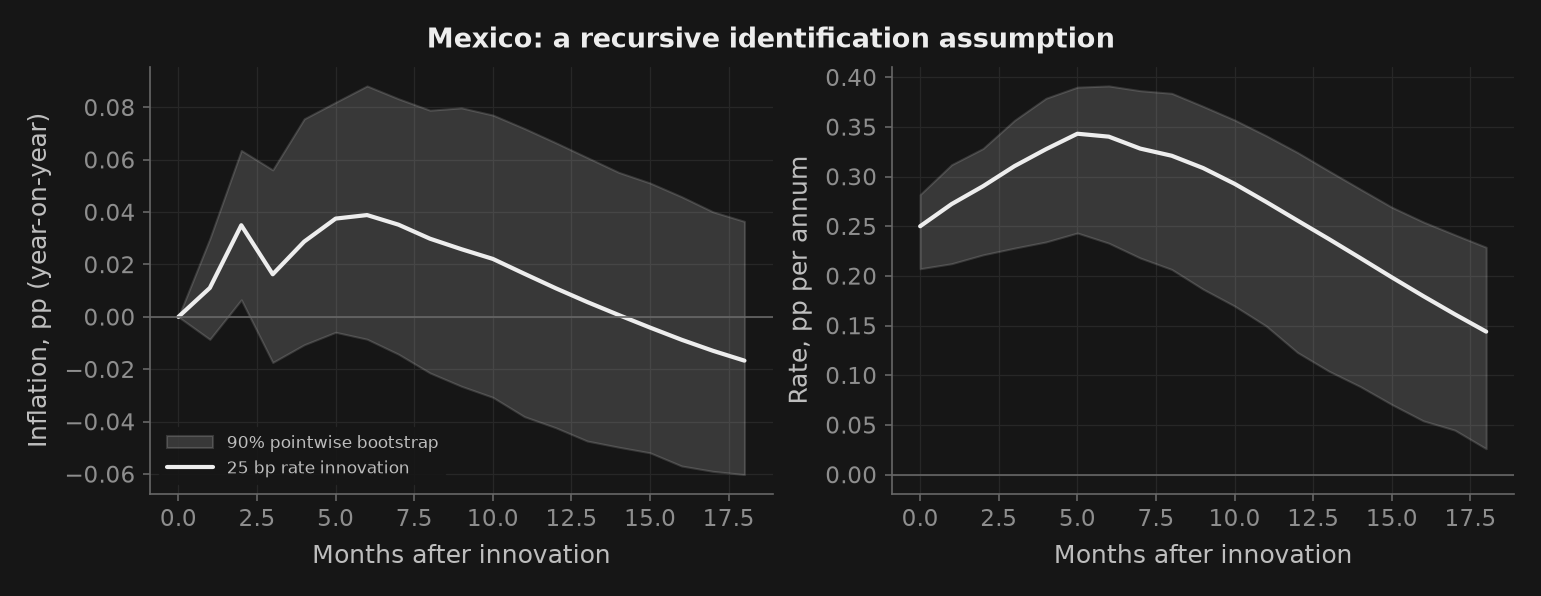

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
for ax, response, label in zip(axes, spec.responses,
                              ("Inflation, pp (year-on-year)", "Rate, pp per annum")):
    row = irf.loc[irf.response.eq(response)]
    ax.fill_between(row.horizon, row.lower, row.upper, color=_nbstyle.BANDA,
                    label="90% pointwise bootstrap")
    ax.plot(row.horizon, row.estimate, label="25 bp rate innovation")
    ax.axhline(0, color=_nbstyle.SPINE, linewidth=0.8)
    ax.set(xlabel="Months after innovation", ylabel=label)
axes[0].legend(fontsize=8)
fig.suptitle("Mexico: a recursive identification assumption")

**Lea el resultado.** Las comprobaciones de impacto verifican la normalización de 25 puntos base y la restricción de cero, no la validez del orden recursivo. Lea la respuesta posterior de inflación en la figura; no imponga un signo negativo después de ver los datos. La identificación conserva el estado `not_checked`. Cambiar los rezagos mantiene la ventana de insumos, pero cambia la longitud de la muestra estimada, registrada en el manifiesto.

In [4]:
short_lag = run_study(data, replace(spec, name="Mexico, three lags", lags=3, n_boot=0))
comparison = compare_studies(mexico, short_lag)
print(comparison.to_frame().loc[lambda f: f.horizon.eq(6),
      ["study", "response", "estimate", "lags", "n_obs", "n_boot"]].round(4).to_string(index=False))
assert mexico.manifest["sample"]["raw_n_obs"] == short_lag.manifest["sample"]["raw_n_obs"]
assert irf.n_obs.iloc[0] == 282 and short_lag.to_frame().n_obs.iloc[0] == 285

                           study      response  estimate  lags  n_obs  n_boot
Mexico recursive rate innovation inflation_yoy    0.0389     6    282     199
Mexico recursive rate innovation       rate_3m    0.3402     6    282     199
              Mexico, three lags inflation_yoy    0.0220     3    285       0
              Mexico, three lags       rate_3m    0.2449     3    285       0


### 2. Una transferencia externa a hogares

La plantilla incluida compila objetivo, presupuesto, malla y proceso de ingresos DP `.mod` para el solucionador EGM existente. Es una calibración trimestral ilustrativa, no un modelo estimado con hogares. La transferencia inicial modifica consumo y ahorro a precios fijos. Ambas trayectorias parten de la misma distribución estacionaria y usan idénticos valores terminales. `A` representa activos al entrar en la fecha: no pueden saltar al impacto.

Mostramos el modelo retenido y la auditoría: convergencia no equivale a precisión de malla. Permanecen visibles los fallos de frontera o Euler. La auditoría registrada corresponde al hogar estacionario; no es una auditoría independiente completa de la transición.

In [5]:
household = run_household(amount=0.05, horizon=40, n_a=100)
print(household.model_source)
print(json.dumps(asdict(household.spec), indent=2))
print(household.inputs.head().round(5).to_string(index=False))
print(household.audits[["check", "status"]].to_string(index=False))
print("Financing:", household.provenance["financing"])
hh = household.to_frame().pivot(index="horizon", columns="response", values="estimate")
transfer = household.evidence["shock_path"].transfer.to_numpy()
np.testing.assert_allclose(hh.A.iloc[0], 0, atol=1e-12)
# Independent resource identity: entering assets plus transfer fund consumption and next assets.
budget_gap = hh.C.iloc[:-1].to_numpy() + hh.A.iloc[1:].to_numpy() - (
    1.01 * hh.A.iloc[:-1].to_numpy() + transfer[:-1])
assert np.max(np.abs(budget_gap)) < 2e-10
print(f"Impact consumption: {hh.C.iloc[0]:.5f}; transfer: {transfer[0]:.5f}")
print(f"Largest aggregate budget gap on paired dates: {np.max(np.abs(budget_gap)):.2e}")


parameters beta gamma r transfer n_a;
beta=.96; gamma=2; r=.01; transfer=0; n_a=100;
state a = 40*linspace(0,1,n_a)^2;
exogenous z = rouwenhorst(rho=.9,sigma=.15,n=5);
model(name='Household transfer experiment');
 c=(1+r)*a+exp(z)+transfer-a(+1);
 reward=crra(c,gamma);
end;
constraints; c>0; end;
aggregates; C=c; A=a; end;
solve(method=egm,tol=1e-10);

{
  "name": "Household transfer",
  "model": "DP EGM household",
  "variables": [
    {
      "name": "C",
      "unit": "consumption units",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "A",
      "unit": "asset units",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "transfer",
      "unit": "consumption units per household",
      "transform": "identity",
      "scale": 1.0
    }
  ],
  "responses": [
    "C",
    "A"
  ],
  "shock": "transfer",
  "frequency": "Q",
  "identification": "calibrated_model_experiment",
  "response_convention": "level_deviation",
  "horizon": 39

Text(0.5, 0.98, 'Illustrative household transfer at fixed prices')

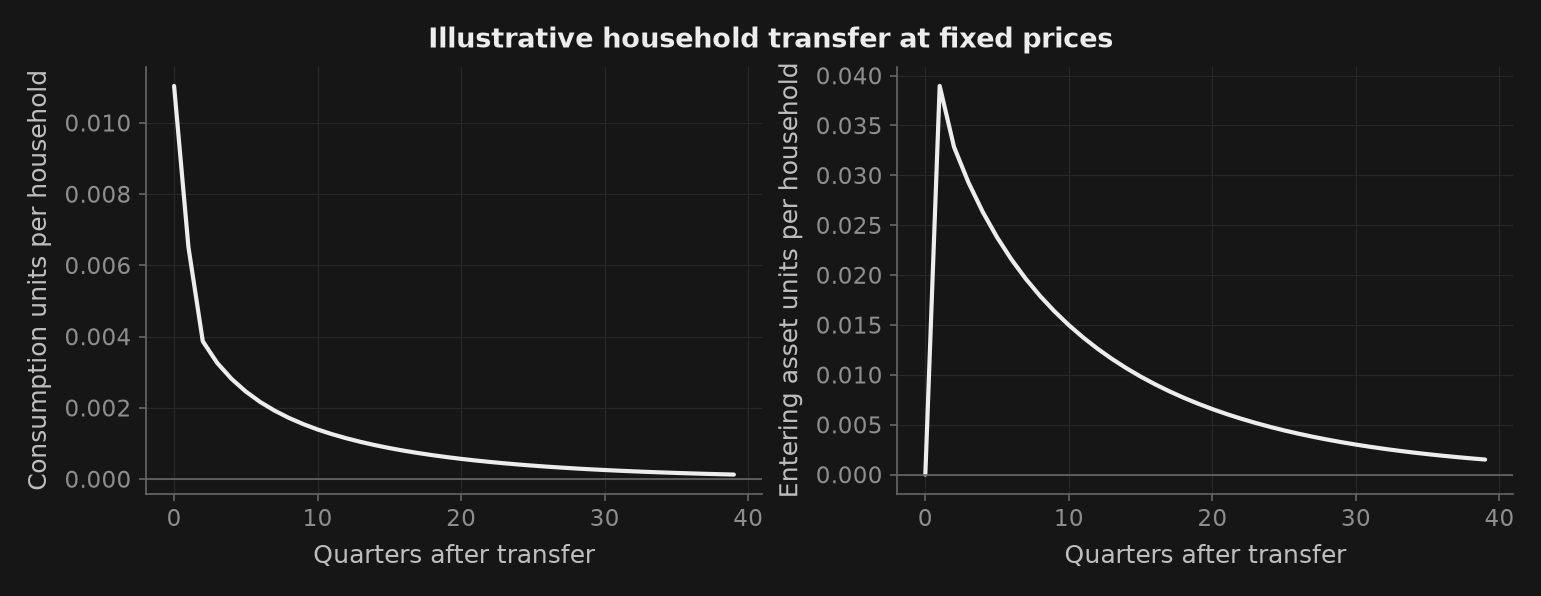

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
for ax, response, label in zip(axes, ("C", "A"),
                              ("Consumption units per household", "Entering asset units per household")):
    ax.plot(hh.index, hh[response], label="Shocked minus zero-transfer path")
    ax.axhline(0, color=_nbstyle.SPINE, linewidth=0.8)
    ax.set(xlabel="Quarters after transfer", ylabel=label)
fig.suptitle("Illustrative household transfer at fixed prices")

**Lea el resultado.** El consumo sube inmediatamente menos que la transferencia; el ahorro traslada recursos a fechas posteriores. La identidad de recursos es una comprobación algebraica independiente de la bandera de convergencia. No verifica optimalidad, precisión de malla ni sostenibilidad fiscal. Esta trayectoria calibrada no tiene bandas estadísticas.

### 3. Un arancel a través de una red productiva

La plantilla conserva los flujos OCDE al agregar a Estados Unidos/México/resto y recursos/manufacturas/otras industrias. Resuelve un arancel estadounidense de 5% sobre manufacturas mexicanas, con devolución de recaudación a suma fija y ahorro externo fijo en unidades del numerario. El precio de recursos estadounidenses vale uno; por supuesto, el trabajo recibe dos tercios del valor agregado. Producción bruta a precios base no es PIB ni bienestar.

Cite OECD (2023), OECD Inter-Country Input-Output Tables, [fuente ICIO](https://www.oecd.org/en/data/datasets/inter-country-input-output-tables.html). Los [términos de atribución y adaptación](https://github.com/jalonso1979/puremacro/blob/main/puremacro/trade/_datafiles/SOURCES.md) también aplican a resultados redistribuidos.

In [7]:
tariff = run_tariff(rate=0.05)
print(json.dumps(asdict(tariff.spec), indent=2))
print(tariff.model_source)
print("Calibration matrix shape:", tariff.inputs.shape)
print(tariff.audits.to_string(index=False))
print(tariff.evidence["tariff_accounting_checks"].to_string(index=False))
trade_response = tariff.to_frame()
base_output = tariff.evidence["baseline_output"].sum(axis=0)
new_output = tariff.evidence["tariff_output"].sum(axis=0)
np.testing.assert_allclose(trade_response.estimate, 100 * (new_output / base_output - 1), atol=1e-10)
print(trade_response[["response", "estimate", "unit"]].round(6).to_string(index=False))

{
  "name": "Manufacturing tariff",
  "model": "Static production network",
  "variables": [
    {
      "name": "output_USA",
      "unit": "percent of baseline gross output",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "output_MEX",
      "unit": "percent of baseline gross output",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "output_REST",
      "unit": "percent of baseline gross output",
      "transform": "identity",
      "scale": 1.0
    },
    {
      "name": "tariff",
      "unit": "ad valorem fraction",
      "transform": "identity",
      "scale": 1.0
    }
  ],
  "responses": [
    "output_USA",
    "output_MEX",
    "output_REST"
  ],
  "shock": "tariff",
  "frequency": "static",
  "identification": "calibrated_model_experiment",
  "response_convention": "static_percent_change",
  "horizon": 0,
  "shock_size": 0.05
}
puremacro.trade: Cobb-Douglas value added, fixed input coefficients, lump-sum duty rebate, fi

[Text(0, 0.5, 'Gross output change at baseline prices (%)'),
 Text(0.0, 1.0, 'Illustrative 5% US tariff on Mexican manufacturing')]

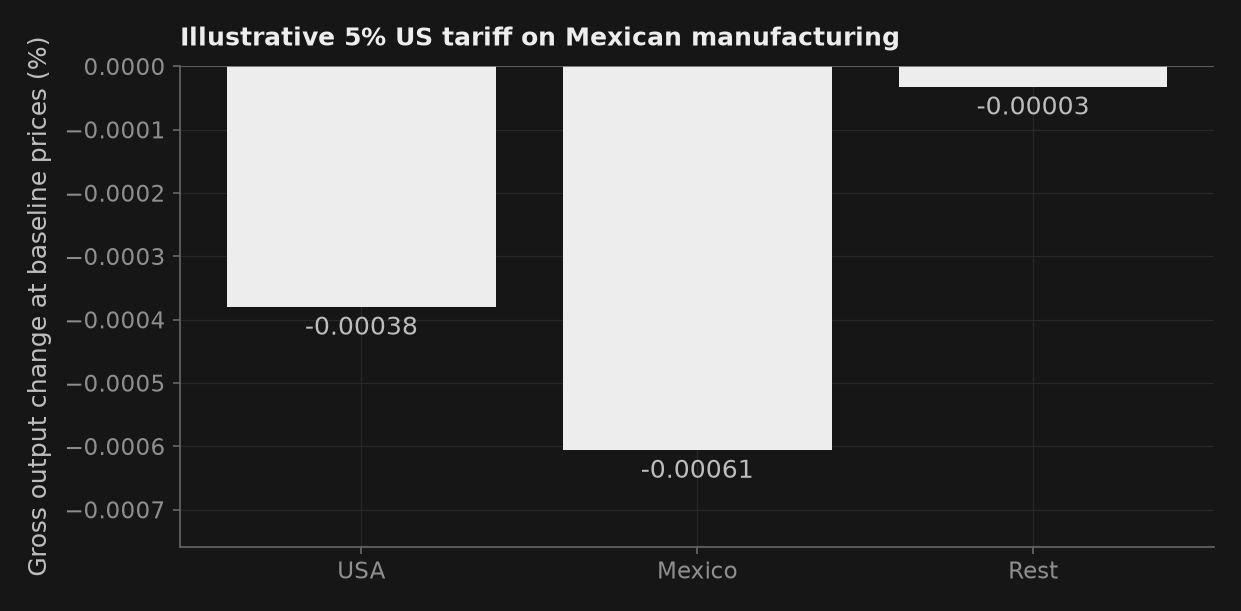

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
bars = ax.bar(["USA", "Mexico", "Rest"], trade_response.estimate, color=_nbstyle.TINTA)
ax.axhline(0, color=_nbstyle.SPINE, linewidth=0.8)
ax.bar_label(bars, fmt="%.5f", padding=4, color=_nbstyle.TEXTO)
ax.margins(y=0.25)
ax.set(ylabel="Gross output change at baseline prices (%)",
       title="Illustrative 5% US tariff on Mexican manufacturing")

**Lea el resultado.** Signos y magnitudes describen esta tecnología y este cierre fiscal. Los residuos físicos mezclan unidades de cantidades, precios, factores y presupuestos; su máximo no es una pérdida monetaria. La contabilidad verifica coherencia interna, no el efecto probable del arancel en la realidad. No se estima incertidumbre paramétrica.

### 4. Exportar, cargar y reproducir el experimento registrado

El archivo contiene insumos, especificación, resultados, auditorías, hashes, versiones y semilla; los escenarios conservan además modelo y tablas de evidencia. La carga verifica un registro ZIP/JSON/NPZ acotado sin ejecutar el modelo ni deserializar objetos pickle. El código verifica todas las tablas retenidas y escribe informes reales en un directorio temporal que después se limpia. Para conservar un informe, ejecute `mexico.write_report("my_mexico_report")` con un nombre **nuevo**: no se sobrescriben directorios existentes. No hace falta ninguna ruta específica de una máquina.

Los hashes exactos describen este entorno y registro. Otra versión de BLAS o bibliotecas puede cambiar resultados de punto flotante. Las comprobaciones muestran repetibilidad aquí, no reproducibilidad binaria universal.

In [9]:
records = {"mexico": mexico, "household": household, "tariff": tariff}
archives = {}
archive_rows = []
for name, original in records.items():
    payload = save_study(original)
    assert isinstance(payload, bytes) and payload == save_study(original)
    archives[name] = payload
    restored = load_study(payload)
    assert restored.spec == original.spec and restored.manifest == original.manifest
    for attr in ("inputs", "data", "audits"):
        pd.testing.assert_frame_equal(getattr(restored, attr), getattr(original, attr))
    pd.testing.assert_frame_equal(restored.to_frame(), original.to_frame())
    if name == "mexico":
        assert restored.inputs.attrs["source"] == original.inputs.attrs["source"]
    if name != "mexico":
        assert restored.model_source == original.model_source
        assert set(restored.evidence) == set(original.evidence)
        for key in original.evidence:
            pd.testing.assert_frame_equal(restored.evidence[key], original.evidence[key])
    archive_rows.append({"experiment": name, "bytes": len(payload),
                         "archive_sha256": hashlib.sha256(payload).hexdigest()})
print(pd.DataFrame(archive_rows).to_string(index=False))
print("Recorded versions:", json.dumps(mexico.manifest["versions"], sort_keys=True))

with TemporaryDirectory(prefix="puremacro-study-demo-") as temporary:
    report_inventory = {}
    for name, original in records.items():
        target = original.write_report(Path(temporary) / name)
        reread = load_study(target / "study.pmstudy")
        pd.testing.assert_frame_equal(reread.to_frame(), original.to_frame())
        if name == "mexico":
            assert reread.inputs.attrs["source"] == original.inputs.attrs["source"]
        report_inventory[name] = sorted(p.name for p in target.iterdir())
    print(json.dumps(report_inventory, indent=2))

repeat = run_study(data, spec)
pd.testing.assert_frame_equal(repeat.to_frame(), mexico.to_frame(), check_exact=True)
assert save_study(repeat) == archives["mexico"]
print("Same-environment seeded VAR rerun and all archive round-trips passed.")

experiment  bytes                                                   archive_sha256
    mexico  21284 5dfa5a0caa4ed9c3a41a72c75904b832c9f708033f45c2e1aacd0edd1d3ad447
 household  60089 fefdec2e502c351b7963478669ac3bbf049b973982c7ea84133fa899cde8d036
    tariff  34671 8767c009717fe19a789bd92f178681bf5b2c1010d2fab88b7669205f12d6f695
Recorded versions: {"numpy": "2.5.4", "pandas": "3.1.0", "puremacro": "5.6.0", "python": "3.12.13", "scipy": "1.18.1"}


{
  "mexico": [
    "audits.csv",
    "manifest.json",
    "report.md",
    "results.csv",
    "results.tex",
    "results.typ",
    "study.pmstudy"
  ],
  "household": [
    "audits.csv",
    "manifest.json",
    "model_source.txt",
    "report.md",
    "results.csv",
    "results.tex",
    "results.typ",
    "study.pmstudy"
  ],
  "tariff": [
    "audits.csv",
    "manifest.json",
    "model_source.txt",
    "report.md",
    "results.csv",
    "results.tex",
    "results.typ",
    "study.pmstudy"
  ]
}


Same-environment seeded VAR rerun and all archive round-trips passed.


No combinamos los tres ejemplos en una comparación de respuestas: innovaciones recursivas mensuales, transferencias trimestrales y aranceles estáticos difieren en unidades, identificación y tiempo. Una explicación no puede anular esas incompatibilidades. LP y VAR también difieren: el adaptador LP reporta $y_{t+h}-y_{t-1}$; este VAR reporta impulsos en niveles.

In [10]:
try:
    compare_studies(mexico, household, comparison_note="These answer different questions.")
except ValueError as exc:
    print("Incompatible comparison rejected:", str(exc))
else:
    raise AssertionError("Unlike monthly VAR and quarterly model responses must not compare")

Incompatible comparison rejected: unlike comparison contracts: variables, responses, shock, frequency, identification, horizon, shock_size, response_convention; observed LP shocks and recursive VAR innovations are not interchangeable


## Su turno

Prediga cómo cambia el VAR lineal al duplicar **la misma innovación identificada**. Cambie `shock_pp` entre 0.10 y 0.50 puntos porcentuales anualizados. La aserción compara toda la respuesta con el escalamiento lineal, manteniendo muestra, orden y dinámica estimada. No afirma exogeneidad en la economía real.

1. Básico: use 0.10 y 0.50. Explique por qué estas unidades no requieren otro factor de 12.
2. Intermedio: compare tres y seis rezagos. ¿Qué conclusiones dependen de la dinámica y por qué difieren las observaciones utilizadas?
3. Avanzado: refine la malla y amplíe el horizonte de hogares. Compare los primeros 20 trimestres con la misma transferencia y convención de distribución inicial; reporte cambios en métricas y fallos de auditoría. Una solución convergente no establece convergencia de malla.

In [11]:
shock_pp = 0.50  # ← change this within [0.10, 0.50], annualized percentage points
assert 0.10 <= shock_pp <= 0.50
scaled = run_study(data, replace(spec, name="Shock normalization exercise", shock_size=shock_pp, n_boot=0))
np.testing.assert_allclose(scaled.to_frame().estimate,
                           mexico.to_frame().estimate * (shock_pp / spec.shock_size),
                           rtol=1e-12, atol=1e-13)
print(f"Response scaling verified for a {100 * shock_pp:.0f} basis-point rate innovation.")

Response scaling verified for a 50 basis-point rate innovation.


## ¿Qué tan completo es?

Son aplicaciones completas y acotadas de motores existentes, no un sistema automático de identificación empírica-estructural. `puremacro.study` también admite LP con exogeneidad declarada y registra escenarios personalizados; `puremacro.validation` ofrece auditorías de alcance explícito y escalas de refinamiento. Las réplicas de señales narrativas describen incertidumbre de medición condicional, no bandas que se sumen al VAR.

Continúe con el [contrato de estudios](https://jalonso1979.github.io/puremacro/docs/es/studies/), la [guía DP](https://jalonso1979.github.io/puremacro/docs/es/dp_modfiles/), [auditorías ampliadas](https://jalonso1979.github.io/puremacro/docs/es/result_audits_extended/) y [contabilidad comercial](https://jalonso1979.github.io/puremacro/docs/es/trade_accounting/). Las tres plantillas incluidas también se ejecutan con `python -m puremacro.examples.study_workflows --output NEW_DIRECTORY`.